# The theorems of *Integrable deformations of Kaleidocycles*: an interactive tour

Companion notebook for the paper "Integrable deformations of Kaleidocycles" by
Shizuo KAJI, Satoshi KAWAKUBO, Nozomu MATSUURA, and Shota SHIGETOMI (in preparation).
Each section states one main theorem, reproduces it numerically with functions from
`kaleidocycle`, and offers sliders to explore it.

| Theorem | Statement (short) | Main functions |
|---|---|---|
| A | mKdV and sine–Gordon flows are complete commuting motions preserving closure and $\mathcal{E}_1$ | `integrate_curvature_flow`, `mkdv_hierarchy_field`, `sine_gordon_field` |
| B | design space has dimension $N-5$; torsion-critical $\Leftrightarrow$ stationary recurrence; $J_c$ loses one rank | `Kaleidocycle.local_dof`, `fixed_torsion_jacobian`, `variational_recurrence_residual`, `qrt_invariant` |
| C | critical configurations are cn families with winding $3\le m\le N-3$, Hessian inertia $(N-m-3,m-3,1)$ | `elliptic_family`, `closing_moduli`, `torsion_hessian`, `jacobi_operator` |
| D | the principal family attains the global minimum $\mu_N$; nearby fibres are $S^1\times S^{N-7}$ | `principal_family`, `minimum_torsion_angle`, `project_to_design_space` |
| E | $k_N=k_\infty+O(N^{-2})$, $\mu_N=C_\infty/N+O(N^{-3})$ | `continuum_constants`, `principal_family` |

**Conventions.** Hinges $B_n$ are unit vectors with $\langle B_n,B_{n+1}\rangle=c=\cos\mu$ and
$B_{n+N}=\sigma B_n$ ($\sigma=1$ oriented, $\sigma=-1$ anti-oriented). The curvature is the
Cayley coordinate $\kappa_n=2\tan(\phi_n/2)$ of the turning angle $\phi_n$, and
$D_n=1+\kappa_n^2/4$. Hinge arrays in the package have shape $(N+1,3)$ and include the
terminal value $B_N=\sigma B_0$.

In [1]:
%matplotlib widget
import warnings

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact

from kaleidocycle import (
    ConstraintConfig,
    Kaleidocycle,
    closing_angle_curve,
    closing_moduli,
    compute_linking_number,
    continuum_constants,
    critical_multiplier,
    elliptic_family,
    first_hamiltonian,
    fixed_torsion_jacobian,
    framed_polygon_from_binormals,
    integrate_curvature_flow,
    jacobi_operator,
    lifted_velocities,
    local_dof,
    minimum_torsion_angle,
    mkdv_hierarchy_field,
    plot_band,
    principal_family,
    project_to_design_space,
    qrt_invariant,
    quadratic_inertia,
    sine_gordon_field,
    torsion_hessian,
    variational_recurrence_residual,
)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 100})


def random_closed(n, oriented, seed):
    # A generic closed design: random hinges projected onto the constraint set.
    return Kaleidocycle(
        n, oriented=oriented, solver_options={"mode": "random_feasible"}, seed=seed
    )

## 1. Configuration spaces and their dimension (Theorem B, first part)

A closed design is cut out of $(S^2)^N$ by $2N+3$ quadratic equations:
$|B_n|^2=1$, $\langle B_n,B_{n+1}\rangle=c$ and the closing condition
$C(B)=\sum_n B_n\times B_{n+1}=0$. At every regular configuration (no two consecutive
centre-line edges antiparallel) these equations are independent, so the design space
$\mathcal{M}_N^\sigma$ with variable torsion has dimension $N-5$ modulo rotations,
and a fixed-torsion fibre has dimension $N-6$.
At a torsion-critical configuration the fixed-torsion Jacobian $J_c$ loses exactly one
rank (Corollary "rank loss"), so the *linearised* fixed-torsion count jumps to $N-5$ even
though the actual fibre (for the principal family) is a single circle.

`Kaleidocycle.local_dof()` uses the full 3-vector alignment of $B_N$ and $\sigma B_0$
(`analysis_config`), so its default count is the design-space dimension $N-5$.

In [2]:
def dimension_report(n=9, oriented=False, seed=0):
    sign = 1 if oriented else -1
    kc = random_closed(n, oriented, seed)
    c = float(kc.hinges[0] @ kc.hinges[1])
    fixed = ConstraintConfig(
        oriented=oriented, full_alignment=True, reference_torsion=c
    )
    rank = np.linalg.matrix_rank(fixed_torsion_jacobian(kc.hinges, sign=sign), tol=1e-9)
    print(f"generic closed design: N={n}, sigma={sign:+d}, mu={np.arccos(c):.4f}")
    print(f"  dim design space / SO(3) (variable torsion): {kc.local_dof()['dof']:2d}"
          f"   expected N-5 = {n - 5}")
    print(f"  dim fixed-torsion fibre / SO(3):             {kc.local_dof(fixed)['dof']:2d}"
          f"   expected N-6 = {n - 6}")
    print(f"  rank J_c:                                    {rank:2d}"
          f"   expected 2N+3 = {2 * n + 3}")
    if not oriented:
        family = principal_family(n)
        hinges = family.binormals(0.3)
        critical = ConstraintConfig(
            oriented=False, full_alignment=True,
            reference_torsion=family.torsion_cosine,
        )
        rank_c = np.linalg.matrix_rank(fixed_torsion_jacobian(hinges, sign=-1), tol=1e-9)
        print(f"principal family (torsion critical): mu_N={family.torsion_angle:.4f}")
        print(f"  rank J_c:                                    {rank_c:2d}"
              f"   expected 2N+2 = {2 * n + 2}")
        print(f"  linearised fixed-torsion DoF:                "
              f"{local_dof(hinges, critical)['dof']:2d}   expected N-5 = {n - 5}")



dimension_report()  # default values

generic closed design: N=9, sigma=-1, mu=2.2271
  dim design space / SO(3) (variable torsion):  4   expected N-5 = 4
  dim fixed-torsion fibre / SO(3):              3   expected N-6 = 3
  rank J_c:                                    21   expected 2N+3 = 21
principal family (torsion critical): mu_N=0.9457
  rank J_c:                                    20   expected 2N+2 = 20
  linearised fixed-torsion DoF:                 4   expected N-5 = 4


Explore with the sliders:

In [3]:
interact(
    dimension_report,
    n=widgets.IntSlider(9, 7, 14, description="N"),
    oriented=False,
    seed=widgets.IntSlider(0, 0, 20, description="seed"),
);

interactive(children=(IntSlider(value=9, description='N', max=14, min=7), Checkbox(value=False, description='o…

## 2. Integrable motions (Theorem A)

The positive semi-discrete mKdV hierarchy $\dot\kappa=X^{(j)}(\kappa)$, with
$X^{(1)}_n=\tfrac12D_n(\kappa_{n+1}-\kappa_{n-1})$, and for $\sigma=-1$ the
semi-discrete sine–Gordon flow, lift to motions of closed Kaleidocycles at fixed
torsion. They are Hamiltonian for $\mathsf P=\mathsf D(\mathsf S-\mathsf S^{-1})\mathsf D$,
commute, and conserve
$\mathcal{E}_1=\sum_n\log(1+\kappa_n^2/4)$ and $\mathcal{E}_2=\tfrac12\sum_n\kappa_n\kappa_{n+1}$.

We start from a closed anti-oriented design that is **not** torsion critical: a random
perturbation of the principal family projected back onto the design space.

N=9, mu=0.96449, max|kappa|=1.671
recurrence residual (nonzero = not critical): 2.070e+00


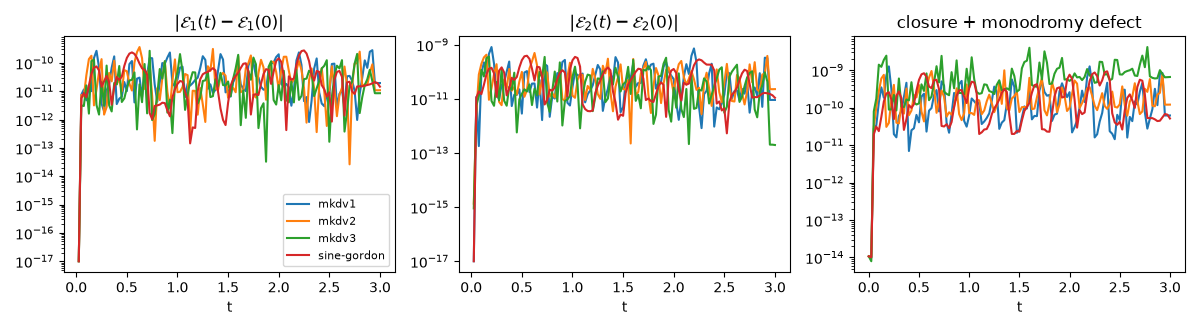

In [4]:
n_demo = 9
rng = np.random.default_rng(1)
base = principal_family(n_demo).binormals(0.4)
perturbed = base[:-1] + 0.25 * rng.standard_normal((n_demo, 3))
perturbed = np.vstack((perturbed, -perturbed[0]))
start = project_to_design_space(perturbed, sign=-1)
initial = framed_polygon_from_binormals(start, sign=-1)
mu_demo = initial.torsion_angle
kappa_demo = initial.curvatures
print(f"N={n_demo}, mu={mu_demo:.5f}, max|kappa|={np.abs(kappa_demo).max():.3f}")
print("recurrence residual (nonzero = not critical):",
      f"{np.abs(variational_recurrence_residual(kappa_demo, sign=-1)).max():.3e}")

times = np.linspace(0.0, 3.0, 121)
flows = ["mkdv1", "mkdv2", "mkdv3", "sine-gordon"]
evolutions = {
    flow: integrate_curvature_flow(
        kappa_demo, mu_demo, times, flow=flow, sign=-1,
        initial_frame=initial.frames[0],
    )
    for flow in flows
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for flow, evolution in evolutions.items():
    configurations = evolution.configurations()
    drift_1 = np.abs(evolution.first_hamiltonian - evolution.first_hamiltonian[0])
    drift_2 = np.abs(evolution.second_hamiltonian - evolution.second_hamiltonian[0])
    defect = [
        np.linalg.norm(conf.closure_residual) + np.linalg.norm(conf.monodromy_residual)
        for conf in configurations
    ]
    axes[0].semilogy(times[1:], drift_1[1:] + 1e-17, label=flow)
    axes[1].semilogy(times[1:], drift_2[1:] + 1e-17)
    axes[2].semilogy(times, np.asarray(defect) + 1e-17)
axes[0].set_title(r"$|\mathcal{E}_1(t)-\mathcal{E}_1(0)|$")
axes[1].set_title(r"$|\mathcal{E}_2(t)-\mathcal{E}_2(0)|$")
axes[2].set_title("closure + monodromy defect")
axes[0].legend(fontsize=8)
for axis in axes:
    axis.set_xlabel("t")
fig.tight_layout()

The flows commute: $\Phi^{(2)}_s\circ\Phi^{(1)}_t=\Phi^{(1)}_t\circ\Phi^{(2)}_s$, and the
first mKdV field never vanishes on a closed configuration.

In [5]:
def flow(kappa, name, duration):
    return integrate_curvature_flow(
        kappa, mu_demo, [0.0, duration], flow=name, sign=-1, rtol=1e-12, atol=1e-14
    ).curvatures[-1]


for first, second in [("mkdv1", "mkdv2"), ("mkdv1", "sine-gordon"), ("mkdv2", "mkdv3")]:
    a = flow(flow(kappa_demo, first, 0.4), second, 0.3)
    b = flow(flow(kappa_demo, second, 0.3), first, 0.4)
    print(f"commutator {first:>6s} vs {second:<11s}: {np.linalg.norm(a - b):.2e}")
smallest = min(
    np.linalg.norm(mkdv_hierarchy_field(row, 1, sign=-1))
    for row in evolutions["mkdv1"].curvatures
)
print(f"min |X^(1)| along the mKdV1 orbit: {smallest:.3f}  (Theorem A: never zero)")

commutator  mkdv1 vs mkdv2      : 3.45e-13
commutator  mkdv1 vs sine-gordon: 2.64e-13
commutator  mkdv2 vs mkdv3      : 7.85e-13
min |X^(1)| along the mKdV1 orbit: 3.554  (Theorem A: never zero)


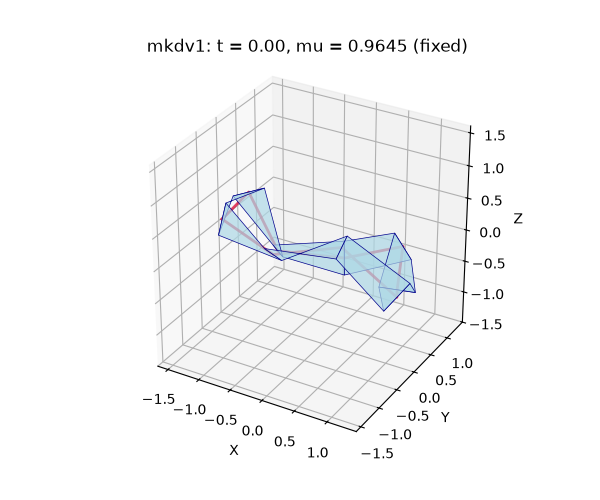

In [6]:
fig_motion = plt.figure(figsize=(6, 5))
ax_motion = fig_motion.add_subplot(projection="3d")


def show_motion(flow="mkdv1", frame=0):
    configuration = evolutions[flow].configuration(frame)
    curve = configuration.vertices - configuration.vertices[:-1].mean(axis=0)
    ax_motion.cla()
    plot_band(curve, configuration.binormals, ax=ax_motion, width=0.25, show_curve=True)
    ax_motion.set_title(f"{flow}: t = {times[frame]:.2f}, mu = {mu_demo:.4f} (fixed)")
    ax_motion.set_box_aspect((1, 1, 1))
    fig_motion.canvas.draw_idle()



show_motion()  # default values

Explore with the sliders:

In [7]:
interact(
    show_motion,
    flow=flows,
    frame=widgets.IntSlider(0, 0, len(times) - 1, description="time step"),
);

interactive(children=(Dropdown(description='flow', options=('mkdv1', 'mkdv2', 'mkdv3', 'sine-gordon'), value='…

## 3. Torsion criticality and the QRT curve (Theorem B)

A regular closed configuration is critical for the torsion iff its curvature solves the
stationary recurrence
$$D_n(\kappa_{n-1}+\kappa_{n+1})=\lambda\kappa_n,\qquad \lambda=2c+\frac{\mathcal{E}_2}{N}.$$
Along the recurrence the biquadratic
$J_\lambda(\kappa_{n-1},\kappa_n)=D_{n-1}D_n-\tfrac{\lambda}{4}\kappa_{n-1}\kappa_n$
is constant: the consecutive pairs lie on one genus-one QRT curve, and the QRT map
advances them by one step. The Jacobi elliptic solutions
$\kappa_n=A\,\mathrm{cn}(\omega+n\delta;k)$ with $\delta=2K(k)m/N$ parametrise these
curves; changing the phase $\omega$ is the common motion of the whole hierarchy.

Move the phase slider: all points travel along the same oval. (Only $\min(N,\,2N/\gcd(2N,m))$ of
the $N$ pairs are distinct, because $\delta/4K=m/2N$; for $N=9$, $m=3$ there are six.) The configuration closes
up only at the closing moduli of Section 4 (the "closing angle" printed below vanishes).

recurrence residual   2.7e-15
QRT invariant spread  1.6e-15
lambda = 1.510957;  2c + E2/N = 1.510957
torsion mu = 0.94572; closing angle (principal value) = +0.0012


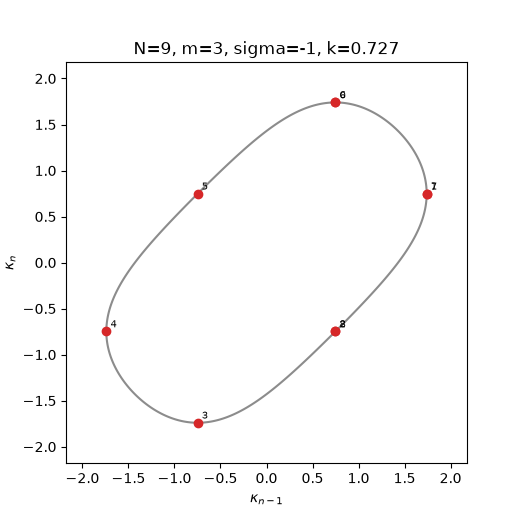

In [8]:
fig_qrt, ax_qrt = plt.subplots(figsize=(5.2, 5.2))


def qrt_picture(n=9, m=3, modulus=0.727, phase=0.0):
    if not 0 < 2 * m < n:
        print("choose 0 < m < N/2")
        return
    family = elliptic_family(n, m, modulus)
    kappa = family.curvatures(phase)
    sign, lam = family.sign, family.multiplier
    level = qrt_invariant(kappa, lam, sign=sign)
    previous = np.r_[sign * kappa[-1], kappa[:-1]]
    span = 1.25 * family.amplitude
    grid = np.linspace(-span, span, 400)
    x, y = np.meshgrid(grid, grid)
    invariant = (1 + x**2 / 4) * (1 + y**2 / 4) - lam / 4 * x * y
    ax_qrt.cla()
    ax_qrt.contour(x, y, invariant, levels=[level[0]], colors="0.55")
    ax_qrt.plot(previous, kappa, "o", color="tab:red")
    for index, (a, b) in enumerate(zip(previous, kappa)):
        ax_qrt.annotate(str(index), (a, b), fontsize=7, xytext=(3, 3),
                        textcoords="offset points")
    ax_qrt.set_xlabel(r"$\kappa_{n-1}$")
    ax_qrt.set_ylabel(r"$\kappa_n$")
    ax_qrt.set_aspect("equal")
    ax_qrt.set_title(f"N={n}, m={m}, sigma={sign:+d}, k={modulus:.3f}")
    fig_qrt.canvas.draw_idle()
    print(f"recurrence residual   {np.abs(variational_recurrence_residual(kappa, lam, sign=sign)).max():.1e}")
    print(f"QRT invariant spread  {np.ptp(level):.1e}")
    print(f"lambda = {lam:.6f};  2c + E2/N = {critical_multiplier(kappa, family.torsion_cosine, sign=sign):.6f}")
    if -1 < family.torsion_cosine < 1:
        print(f"torsion mu = {family.torsion_angle:.5f}; closing angle (principal value) "
              f"= {family.closing_angle(phase):+.4f}")
    else:
        print(f"c_m(k) = {family.torsion_cosine:.4f} is outside (-1, 1): no geometric ring")



qrt_picture()  # default values

Explore with the sliders:

In [9]:
interact(
    qrt_picture,
    n=widgets.IntSlider(9, 7, 16, description="N"),
    m=widgets.IntSlider(3, 1, 7, description="m"),
    modulus=widgets.FloatSlider(0.727, min=0.05, max=0.99, step=0.001, readout_format=".3f"),
    phase=widgets.FloatSlider(0.0, min=0.0, max=8.0, step=0.02),
);

interactive(children=(IntSlider(value=9, description='N', max=16, min=7), IntSlider(value=3, description='m', …

On the critical locus all hierarchy fields become parallel: $X^{(2)}=\lambda X^{(1)}$,
every $X^{(j)}$ is a constant multiple of $X^{(1)}$, and for $\sigma=-1$ so is the
sine–Gordon field. Off the locus (the perturbed configuration of Section 2) they are
independent.

In [10]:
def parallel_report(kappa, mu, label):
    first = mkdv_hierarchy_field(kappa, 1, sign=-1)
    fields = {f"X^({j})": mkdv_hierarchy_field(kappa, j, sign=-1) for j in (2, 3, 4)}
    fields["X^(sG)"] = sine_gordon_field(kappa, mu, sign=-1)
    print(label)
    for name, field in fields.items():
        scale = field @ first / (first @ first)
        residual = np.linalg.norm(field - scale * first) / np.linalg.norm(field)
        print(f"  {name:7s} = {scale:+.6f} X^(1)   relative residual {residual:.1e}")


critical = principal_family(n_demo)
parallel_report(critical.curvatures(0.4), critical.torsion_angle,
                f"critical: principal family N={n_demo} (lambda = {critical.multiplier:.6f})")
parallel_report(kappa_demo, mu_demo, "non-critical: perturbed configuration of Section 2")

critical: principal family N=9 (lambda = 1.511220)
  X^(2)   = +1.511220 X^(1)   relative residual 6.4e-16
  X^(3)   = +1.261346 X^(1)   relative residual 9.5e-16
  X^(4)   = -1.184094 X^(1)   relative residual 2.0e-15
  X^(sG)  = -0.548956 X^(1)   relative residual 5.5e-16
non-critical: perturbed configuration of Section 2
  X^(2)   = +1.376720 X^(1)   relative residual 2.8e-01
  X^(3)   = +1.147520 X^(1)   relative residual 6.0e-03
  X^(4)   = -1.762372 X^(1)   relative residual 2.4e-01
  X^(sG)  = -0.531119 X^(1)   relative residual 1.2e-01


## 4. Elliptic families and the torsion index (Theorem C)

For $0<m<N/2$ the cn family has torsion branch
$c_m(k)=\mathrm{cn}\,\delta+\frac{\mathrm{sn}\,\delta}{\mathrm{dn}\,\delta}Z(\delta;k)$, and it
closes when the frame-monodromy defect, a rotation about the conserved multiplier vector
$\mathbf M$ through the *closing angle* $\Theta(k)$, is trivial. $\Theta$ decreases
strictly from $0$ to $-m\pi$, so there are exactly $\lfloor(m-1)/2\rfloor$ closing moduli
($\Theta=-2\pi j$), anti-oriented for odd $m$ and oriented for even $m$; $m=1,2$ never close.

At a closed member the Hessian of $\mu$ on the design space modulo rotations has inertia
$(N-m-3,\ m-3,\ 1)$: the principal family $m=3$ is a local minimum, every other winding is a
saddle, and the zero direction is the phase circle. The Jacobi operator
$\mathcal{J}_\lambda=\mathrm{Hess}(\mathcal{E}_2-\lambda\mathcal{E}_1)$ has inertia $(m,N-m-1,1)$ with
kernel spanned by $X^{(1)}$.

 m  j  sigma   k_close     mu       Hess(mu)   expected   Jacobi
 3  1  -1   0.693664  0.759648   (5, 0, 1)  (5, 0, 1)  (3, 7, 1)  ok
 4  1  +1   0.589256  1.096677   (4, 1, 1)  (4, 1, 1)  (4, 6, 1)  ok
 5  1  -1   0.545734  1.414088   (3, 2, 1)  (3, 2, 1)  (5, 5, 1)  ok
 5  2  -1   0.915775  1.311859   (3, 2, 1)  (3, 2, 1)  (5, 5, 1)  ok


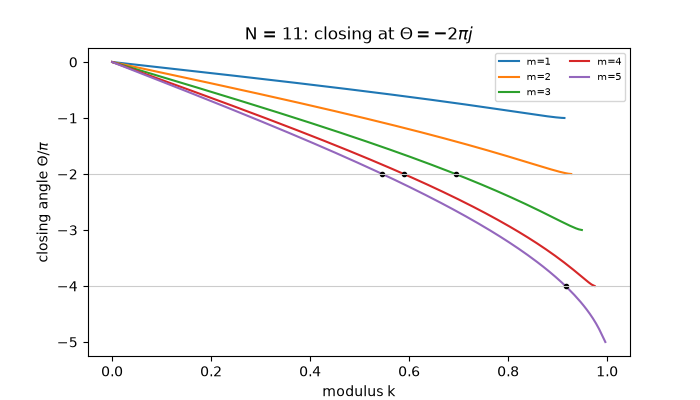

In [11]:
fig_theta, ax_theta = plt.subplots(figsize=(7, 4))


def index_table(n=11):
    ax_theta.cla()
    rows = []
    for m in range(1, (n + 1) // 2):
        if 2 * m >= n:
            continue
        moduli, theta = closing_angle_curve(n, m, samples=160)
        ax_theta.plot(moduli, theta / np.pi, label=f"m={m}")
        for level, k in enumerate(closing_moduli(n, m), start=1):
            family = elliptic_family(n, m, k)
            hessian = torsion_hessian(family.binormals(0.37), sign=family.sign)
            jacobi = quadratic_inertia(
                jacobi_operator(family.curvatures(0.37), family.multiplier, sign=family.sign)
            )
            rows.append((m, level, family.sign, k, family.torsion_angle,
                         hessian.inertia, (n - m - 3, m - 3, 1), jacobi))
            ax_theta.plot(k, -2 * level, "k.")
    for level in range(1, n // 4 + 1):
        ax_theta.axhline(-2 * level, color="0.8", lw=0.8)
    ax_theta.set_xlabel("modulus k")
    ax_theta.set_ylabel(r"closing angle $\Theta/\pi$")
    ax_theta.set_title(f"N = {n}: closing at $\\Theta=-2\\pi j$")
    ax_theta.legend(fontsize=7, ncol=2)
    fig_theta.canvas.draw_idle()
    print(" m  j  sigma   k_close     mu       Hess(mu)   expected   Jacobi")
    for m, level, sign, k, mu, inertia, expected, jacobi in rows:
        flag = "ok" if inertia == expected else "MISMATCH"
        print(f"{m:2d} {level:2d}  {sign:+d}   {k:.6f}  {mu:.6f}   {inertia}  {expected}"
              f"  {jacobi}  {flag}")



index_table()  # default values

Explore with the sliders:

In [12]:
interact(index_table, n=widgets.IntSlider(11, 7, 17, description="N"));

interactive(children=(IntSlider(value=11, description='N', max=17, min=7), Output()), _dom_classes=('widget-in…

**Mirror duality and winding.** The mirror $B_n\mapsto(-1)^nB_n$ sends $\mu$ to $\pi-\mu$ and
$\sigma$ to $(-1)^N\sigma$; it exchanges the positive and negative indices, so the mirror of the
principal family is a local *maximum*. The winding $m$ is also the number of sign changes of the
(twisted) curvature sequence, and the number of times the binormal path crosses the equator
$\mathbf M^\perp$, because $\langle\mathbf M,B_n\rangle=-\kappa_n/(2N)$.

In [13]:
for n in (7, 8, 9):
    family = principal_family(n)
    hinges = family.binormals(0.3)
    mirrored = hinges * (-1.0) ** np.arange(n + 1)[:, None]
    mirror_sign = (-1) ** n * family.sign
    inertia = torsion_hessian(mirrored, sign=mirror_sign).inertia
    kappa = family.curvatures(0.3)
    twisted = np.r_[kappa, family.sign * kappa[0]]
    changes = int(np.sum(twisted[:-1] * twisted[1:] < 0))
    side = hinges[:-1] @ family.multiplier_vector(0.3)
    print(f"N={n}: mirror mu = {np.arccos(mirrored[0] @ mirrored[1]):.4f} "
          f"(pi - mu_N = {np.pi - family.torsion_angle:.4f}), sigma={mirror_sign:+d}, "
          f"Hess inertia {inertia} (local max);  sign changes {changes}, "
          f"<M,B_n> = -kappa_n/(2N): {np.allclose(side, -kappa / (2 * n))}")

N=7: mirror mu = 1.8707 (pi - mu_N = 1.8707), sigma=+1, Hess inertia (0, 1, 1) (local max);  sign changes 3, <M,B_n> = -kappa_n/(2N): True
N=8: mirror mu = 2.0600 (pi - mu_N = 2.0600), sigma=-1, Hess inertia (0, 2, 1) (local max);  sign changes 3, <M,B_n> = -kappa_n/(2N): True
N=9: mirror mu = 2.1959 (pi - mu_N = 2.1959), sigma=+1, Hess inertia (0, 3, 1) (local max);  sign changes 3, <M,B_n> = -kappa_n/(2N): True


## 5. The global minimum and nearby configuration spaces (Theorem D)

The principal family attains the global minimum $\mu_N$ of the torsion angle over **all**
closed anti-oriented configurations, its phase circle is the entire minimum fibre, and
$\mu_{N+2}<\mu_N$. The table compares with the values reported in the paper (which agree with
the critical angles of Schönke and Fried). The centre lines have normalised ribbon
self-linking $3/2$ (`compute_linking_number` returns $2\,\mathrm{SL}$).

 N   k_N            mu_N/pi    paper      SL over 4 phases
 7   0.7976236789  0.404551  0.40455    [1.5 1.5 1.5 1.5]
 8   0.7551128995  0.344269  0.34427    [1.5 1.5 1.5 1.5]
 9   0.7271056052  0.301015  0.30101    [1.5 1.5 1.5 1.5]
10   0.7076889655  0.268001  0.26800    [1.5 1.5 1.5 1.5]
11   0.6936642932  0.241804  0.24180    [1.5 1.5 1.5 1.5]
12   0.6831942289  0.220433  0.22043    [1.5 1.5 1.5 1.5]


15   0.6638334416  0.174595  0.17459    [1.5 1.5 1.5 1.5]


21   0.6474744221  0.123687  0.12369    [1.5 1.5 1.5 1.5]


33   0.6375666526  0.078324  0.07832    [1.5 1.5 1.5 1.5]


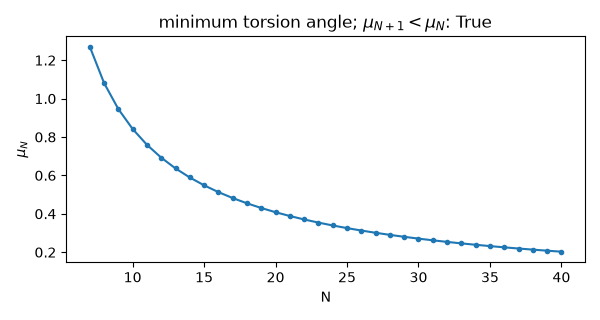

In [14]:
paper_mu_over_pi = {7: 0.40455, 8: 0.34427, 9: 0.30101, 10: 0.26800, 11: 0.24180,
                    12: 0.22043, 15: 0.17459, 21: 0.12369, 33: 0.07832}
print(" N   k_N            mu_N/pi    paper      SL over 4 phases")
for n, value in paper_mu_over_pi.items():
    family = principal_family(n)
    links = [compute_linking_number(family.binormals(p)) / 2
             for p in np.linspace(0, family.phase_period, 4, endpoint=False)]
    print(f"{n:2d}   {family.modulus:.10f}  {family.torsion_angle / np.pi:.6f}  "
          f"{value:.5f}    {np.round(links, 6)}")

ns = np.arange(7, 41)
minima = np.array([minimum_torsion_angle(n) for n in ns])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ns, minima, "o-", ms=3)
ax.set_xlabel("N")
ax.set_ylabel(r"$\mu_N$")
ax.set_title(r"minimum torsion angle; $\mu_{N+1}<\mu_N$: " + str(bool(np.all(np.diff(minima) < 0))))
fig.tight_layout()

**Global minimality, seen from random designs.** Random closed anti-oriented designs never have
torsion below $\mu_N$. For $N=7$ and $N=8$ the bending energy is even a function of the torsion
alone (Theorem "energy selection"):
$\mathcal{E}_1=2\log\frac{1024}{5}+14\log\sin\frac\mu2$ for $N=7$ and
$e^{-\mathcal{E}_1/2}=\frac{|c|(3+2c^2)}{16s^7}$ for $N=8$.

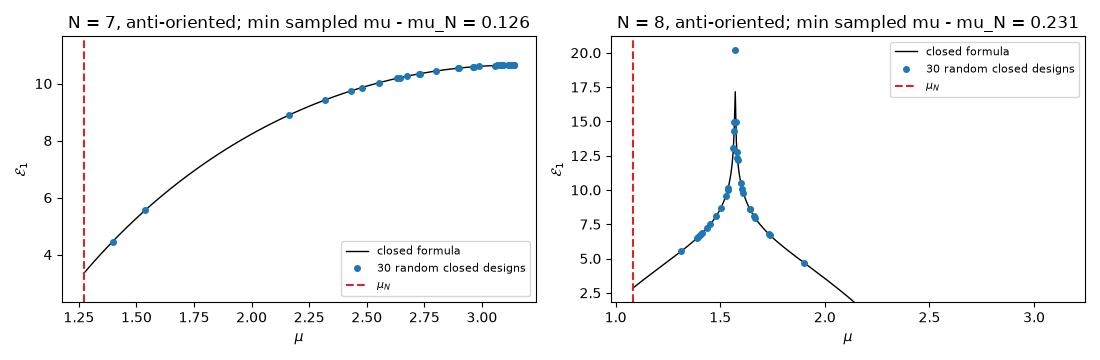

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for axis, n in zip(axes, (7, 8)):
    mus, energies = [], []
    for seed in range(30):
        try:
            sample = framed_polygon_from_binormals(random_closed(n, False, seed).hinges, sign=-1)
        except ValueError:  # folded sample (turning angle pi)
            continue
        mus.append(sample.torsion_angle)
        energies.append(first_hamiltonian(sample.curvatures))
    mu_n = minimum_torsion_angle(n)
    grid = np.linspace(mu_n, np.pi - 1e-3, 400)
    if n == 7:
        curve = 2 * np.log(1024 / 5) + 14 * np.log(np.sin(grid / 2))
    else:
        c, s = np.cos(grid), np.sin(grid)
        curve = -2 * np.log(np.abs(c) * (3 + 2 * c**2) / (16 * s**7))
    axis.plot(grid, curve, "k-", lw=1, label="closed formula")
    axis.plot(mus, energies, "o", ms=4, label=f"{len(mus)} random closed designs")
    axis.axvline(mu_n, color="tab:red", ls="--", label=r"$\mu_N$")
    axis.set_ylim(min(curve[0], min(energies)) - 1, max(energies) + 1)
    axis.set_xlabel(r"$\mu$")
    axis.set_ylabel(r"$\mathcal{E}_1$")
    axis.set_title(f"N = {n}, anti-oriented; min sampled mu - mu_N = {min(mus) - mu_n:.3f}")
    axis.legend(fontsize=8)
fig.tight_layout()

**Nearby fibres.** Near the minimum, $\mu=\mu_N+|v|^2$ in Morse–Bott coordinates
$(\theta,v)\in S^1\times\mathbb R^{N-6}$, so the fibre at $\mu_N+\varepsilon$ is
$S^1\times S^{N-7}$: **two circles for $N=7$** and **a torus for $N=8$**. We step off the minimum
circle along the positive Hessian direction (both signs), project back onto the design space,
and follow the first mKdV flow, which keeps the torsion fixed. The plot shows the orbits in the
coordinates $(\kappa_0,\kappa_1)$.

For $N=7$ the two sides give two separate closed orbits. For $N=8$ both sides lie on one torus,
which the orbit fills densely, and $X^{(1)},X^{(2)}$ span the fibre (Corollary
"small-linkage integrable fibres").

N=7, side +1: fibre dim / SO(3) = 1, span of X1, X2 / rotations = 1


N=7, side -1: fibre dim / SO(3) = 1, span of X1, X2 / rotations = 1
N=7: distance between the two orbits in curvature space = 0.956


N=8, side +1: fibre dim / SO(3) = 2, span of X1, X2 / rotations = 2


N=8, side -1: fibre dim / SO(3) = 2, span of X1, X2 / rotations = 2
N=8: distance between the two orbits in curvature space = 0.004


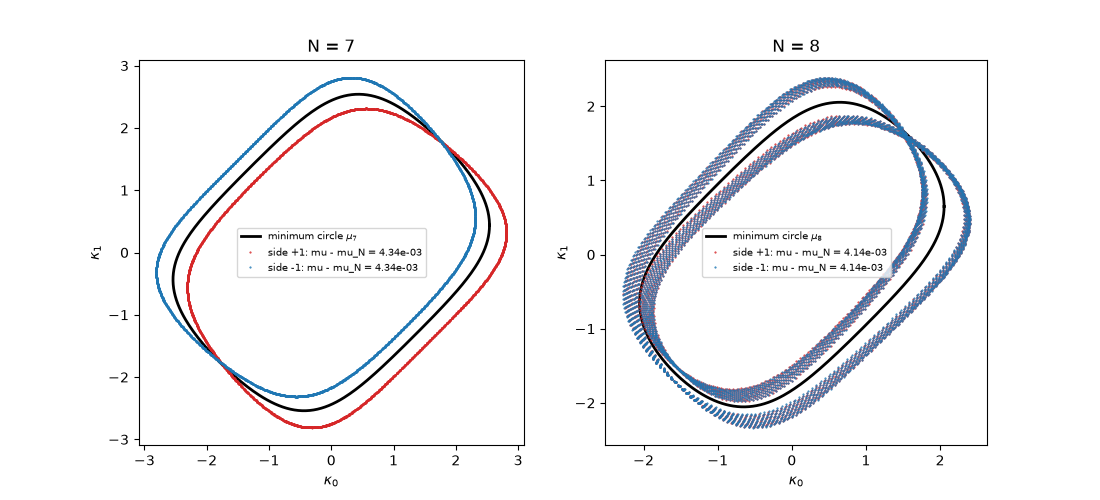

In [16]:
fig_fibre, axes_fibre = plt.subplots(1, 2, figsize=(11, 5))


def off_minimum(n, amount, direction):
    family = principal_family(n)
    hinges = family.binormals(0.3)
    hessian = torsion_hessian(hinges, sign=-1)
    vector = hessian.eigenvectors[:, -1]  # largest positive curvature of mu
    moved = hinges[:-1] + direction * amount * vector[: 3 * n].reshape(n, 3)
    moved = np.vstack((moved, -moved[0]))
    return family, project_to_design_space(moved, sign=-1)


def fibre_picture(amount=0.15, duration=150.0):
    for axis, n in zip(axes_fibre, (7, 8)):
        axis.cla()
        family = principal_family(n)
        phases = np.linspace(0, family.phase_period, 400)
        circle = np.array([family.curvatures(p)[:2] for p in phases])
        axis.plot(*circle.T, "k-", lw=2, label=rf"minimum circle $\mu_{n}$")
        orbits = []
        for direction, colour in ((1, "tab:red"), (-1, "tab:blue")):
            _, hinges = off_minimum(n, amount, direction)
            start = framed_polygon_from_binormals(hinges, sign=-1)
            orbit = integrate_curvature_flow(
                start.curvatures, start.torsion_angle,
                np.linspace(0, duration, 5000), flow="mkdv1", sign=-1,
            ).curvatures
            orbits.append(orbit)
            axis.plot(orbit[:, 0], orbit[:, 1], ".", ms=1, color=colour,
                      label=f"side {direction:+d}: mu - mu_N = "
                            f"{start.torsion_angle - family.torsion_angle:.2e}")
            rank = np.linalg.matrix_rank(fixed_torsion_jacobian(hinges, sign=-1), tol=1e-9)
            velocities = [lifted_velocities(start, flow=f)[1][:-1].ravel()
                          for f in ("mkdv1", "mkdv2")]
            rotations = [np.cross(e, hinges[:-1]).ravel() for e in np.eye(3)]
            span = np.linalg.matrix_rank(np.column_stack(velocities + rotations), tol=1e-8) - 3
            print(f"N={n}, side {direction:+d}: fibre dim / SO(3) = {3 * n - rank - 3}, "
                  f"span of X1, X2 / rotations = {span}")
        gap = min(np.linalg.norm(orbits[0] - point, axis=1).min() for point in orbits[1][::25])
        print(f"N={n}: distance between the two orbits in curvature space = {gap:.3f}")
        axis.set_title(f"N = {n}")
        axis.set_xlabel(r"$\kappa_0$")
        axis.set_ylabel(r"$\kappa_1$")
        axis.set_aspect("equal")
        axis.legend(fontsize=7, loc="center")
    fig_fibre.canvas.draw_idle()



fibre_picture()  # default values

Explore with the sliders:

In [17]:
interact(
    fibre_picture,
    amount=widgets.FloatSlider(0.15, min=0.02, max=0.3, step=0.01, description="step"),
    duration=widgets.FloatSlider(150.0, min=20.0, max=400.0, step=10.0, description="time"),
);

interactive(children=(FloatSlider(value=0.15, description='step', max=0.3, min=0.02, step=0.01), FloatSlider(v…

## 6. The continuum limit (Theorem E)

With $a=1-E/K$, $t=\sqrt{1-2a}$, $d=\sqrt{a^2+k^2t^2}$ and
$g(k)=6Ktd/(k(1-k^2))$, the limiting modulus solves $\int_0^{k_\infty}g=2\pi$ and
$C_\infty=6K(k_\infty)t(k_\infty)$. Then $k_N=k_\infty+O(N^{-2})$ and
$\mu_N=C_\infty/N+O(N^{-3})$; the rescaled curvature $N\kappa_n$ at $x=n/N$ converges to
$f_\infty(x)=12k_\infty K_\infty\,\mathrm{cn}(2K_\infty z_0+6K_\infty x;k_\infty)$.

k_inf = 0.6309247559   (paper 0.6309247559)
C_inf = 8.0934956856   (paper 8.0934956856)


N^2 (k_N - k_inf):     [7.1947 7.1921 7.1902]
N^2 (N mu_N - C_inf):  [28.605  28.5869 28.5741]


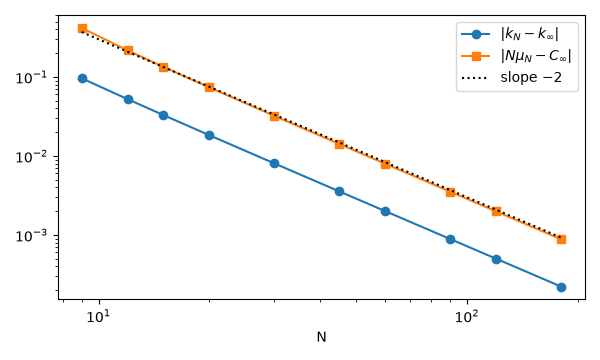

In [18]:
k_inf, c_inf = continuum_constants()
print(f"k_inf = {k_inf:.10f}   (paper 0.6309247559)")
print(f"C_inf = {c_inf:.10f}   (paper 8.0934956856)")

ns = np.array([9, 12, 15, 20, 30, 45, 60, 90, 120, 180])
families = [principal_family(int(n)) for n in ns]
k_error = np.array([abs(f.modulus - k_inf) for f in families])
mu_error = np.array([abs(n * f.torsion_angle - c_inf) for n, f in zip(ns, families)])
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.loglog(ns, k_error, "o-", label=r"$|k_N-k_\infty|$")
ax.loglog(ns, mu_error, "s-", label=r"$|N\mu_N-C_\infty|$")
ax.loglog(ns, 30 * ns**-2.0, "k:", label=r"slope $-2$")
ax.set_xlabel("N")
ax.legend()
fig.tight_layout()
print("N^2 (k_N - k_inf):    ", np.round((k_error * ns**2)[-3:], 4))
print("N^2 (N mu_N - C_inf): ", np.round((mu_error * ns**2)[-3:], 4))

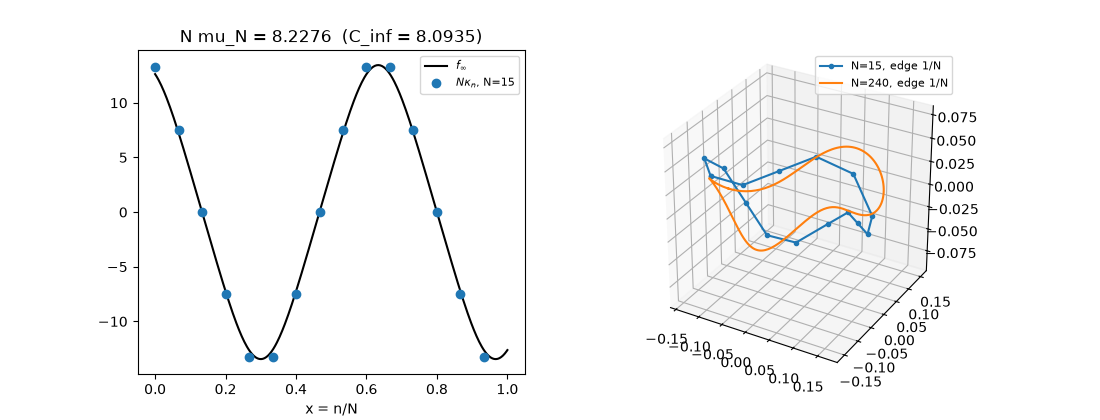

In [19]:
from scipy.special import ellipj, ellipk

fig_limit = plt.figure(figsize=(11, 4.2))
ax_profile = fig_limit.add_subplot(1, 2, 1)
ax_curve = fig_limit.add_subplot(1, 2, 2, projection="3d")
quarter_inf = ellipk(k_inf**2)


def continuum_picture(n=15, z0=0.1):
    family = principal_family(n)
    phase = 2 * family.quarter_period * z0
    x = np.linspace(0, 1, 400)
    limit = 12 * k_inf * quarter_inf * ellipj(2 * quarter_inf * z0 + 6 * quarter_inf * x,
                                              k_inf**2)[1]
    ax_profile.cla()
    ax_profile.plot(x, limit, "k-", label=r"$f_\infty$")
    ax_profile.plot(np.arange(n) / n, n * family.curvatures(phase), "o",
                    label=rf"$N\kappa_n$, N={n}")
    ax_profile.set_xlabel("x = n/N")
    ax_profile.legend(fontsize=8)
    ax_profile.set_title(f"N mu_N = {n * family.torsion_angle:.4f}  (C_inf = {c_inf:.4f})")
    ax_curve.cla()
    for size, style in ((n, "o-"), (240, "-")):
        member = principal_family(size)
        vertices = member.configuration(2 * member.quarter_period * z0).vertices / size
        ax_curve.plot(*(vertices - vertices[:-1].mean(axis=0)).T, style, ms=3,
                      label=f"N={size}, edge 1/N")
    ax_curve.set_box_aspect((1, 1, 1))
    ax_curve.legend(fontsize=8)
    fig_limit.canvas.draw_idle()



continuum_picture()  # default values

Explore with the sliders:

In [20]:
interact(
    continuum_picture,
    n=widgets.IntSlider(15, 7, 60, description="N"),
    z0=widgets.FloatSlider(0.1, min=0.0, max=1.0, step=0.01, description="z0"),
);

interactive(children=(IntSlider(value=15, description='N', max=60, min=7), FloatSlider(value=0.1, description=…

## Summary

All quantitative statements checked here agree with the paper to numerical precision: the
dimension counts and the rank loss of Theorem B, the commuting conserved flows of Theorem A,
the inertia $(N-m-3,m-3,1)$ of Theorem C for every closing branch, the table of $\mu_N$, global
minimality, self-linking and the near-minimum fibres of Theorem D, and the constants and
convergence rates of Theorem E. The automated versions of these checks are in
`tests/test_elliptic.py` and `tests/test_integrable.py`.

Numerical note: `scipy.special.ellipeinc` returns wrong values at isolated arguments (e.g.
$\phi=1.2821$, $m=0.7167$ in SciPy 1.17–1.18); `kaleidocycle.jacobi_zeta` therefore uses
Carlson's symmetric integrals.